# Sakura Data (Somei-yoshino)

1. Full bloom dates: Check for missing data and explore long-term trends in when full bloom occurs
2. Time between flowering and full bloom: Check for missing data and explore how this interval varies across years and locations


## 1. Full bloom dates

In [188]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
from pathlib import Path

In [189]:
# flower = pd.read_csv('02_01_sakura_flowering_1953_2025.csv')
# full_bloom = pd.read_csv('02_02_sakura_full_bloom_1953_2025.csv')

In [190]:
CONFIG_FILE = Path("../../config.json").resolve()

with CONFIG_FILE.open(encoding="utf-8-sig") as file:
    config = json.load(file)

In [191]:
PROJECT_DIR = CONFIG_FILE.parent
FLOWERING_FILE = PROJECT_DIR / config['sakura']['flowering_file']
FULL_BLOOM_FILE = PROJECT_DIR / config['sakura']['full_bloom_file']
SPECIES_FILE = PROJECT_DIR / config['station_metadata']['species_file']

flower = pd.read_csv(FLOWERING_FILE)
full_bloom = pd.read_csv(FULL_BLOOM_FILE)
species = pd.read_csv(SPECIES_FILE)

In [192]:
full_bloom.head(1)

,station_id,year,full_bloom_date
0,401,1953,30/5/1953


In [193]:
species['cherry_species'].value_counts()

cherry_species
Somei-yoshino      82
Ezo-yamazakura     10
Hikan-zakura        9
Chishima-zakura     1
Name: count, dtype: int64

### check for null 

In [194]:
full_bloom.isnull().sum()

station_id            0
year                  0
full_bloom_date    1287
dtype: int64

### transform the date to day of year

In [195]:



full_bloom["full_bloom_date"] = pd.to_datetime(
    full_bloom["full_bloom_date"],
    dayfirst=True
)


full_bloom["full_bloom_doy"] = full_bloom["full_bloom_date"].dt.dayofyear


full_bloom[["station_id", "year", "full_bloom_date", "full_bloom_doy"]].head()

,station_id,year,full_bloom_date,full_bloom_doy
0,401,1953,1953-05-30,150.0
1,401,1954,1954-05-27,147.0
2,401,1955,1955-05-23,143.0
3,401,1956,1956-05-14,135.0
4,401,1957,1957-05-22,142.0


### filter for somei-yoshino

In [196]:
all_full_bloom = pd.merge(
    full_bloom,
    species,
    on='station_id',
    how='left'
)
print('Before', full_bloom.shape)
print('Merge species', all_full_bloom.shape) 

somei_full_bloom = all_full_bloom.query('cherry_species == "Somei-yoshino"')
print('Filter for somei-yoshino', somei_full_bloom.shape)
print('Number of Somei-Yoshino station', somei_full_bloom['station_id'].nunique())


Before (7446, 4)
Merge species (7446, 5)
Filter for somei-yoshino (5986, 5)
Number of Somei-Yoshino station 82


## simple visualization(before dealing with null values )

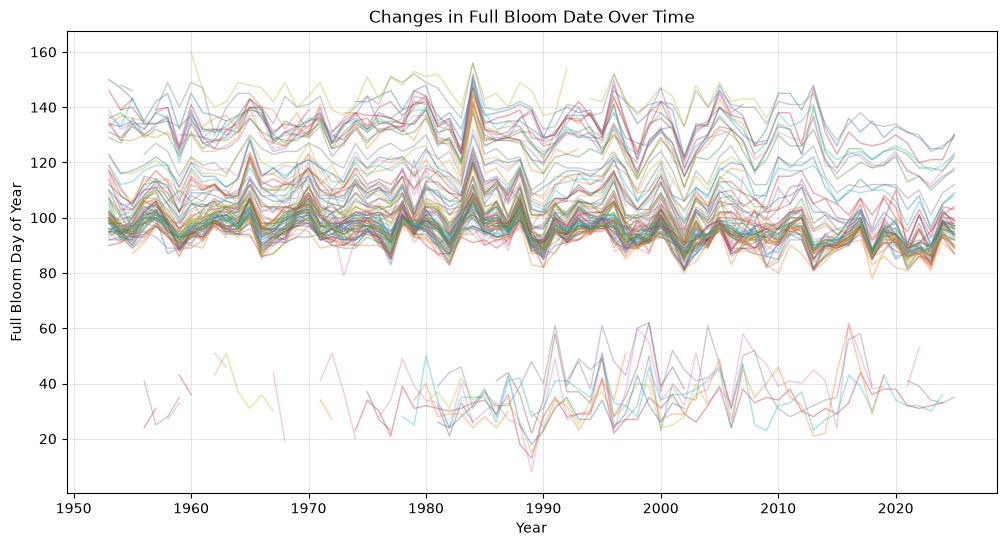

In [197]:
plt.figure(figsize=(12, 6))

for station_id, group in full_bloom.groupby("station_id"):
    group = group.sort_values("year")
    
    plt.plot(
        group["year"],
        group["full_bloom_doy"],
        alpha=0.4,
        linewidth=1
    )

plt.xlabel("Year")
plt.ylabel("Full Bloom Day of Year")
plt.title("Changes in Full Bloom Date Over Time")

plt.grid(alpha=0.3)
plt.show()

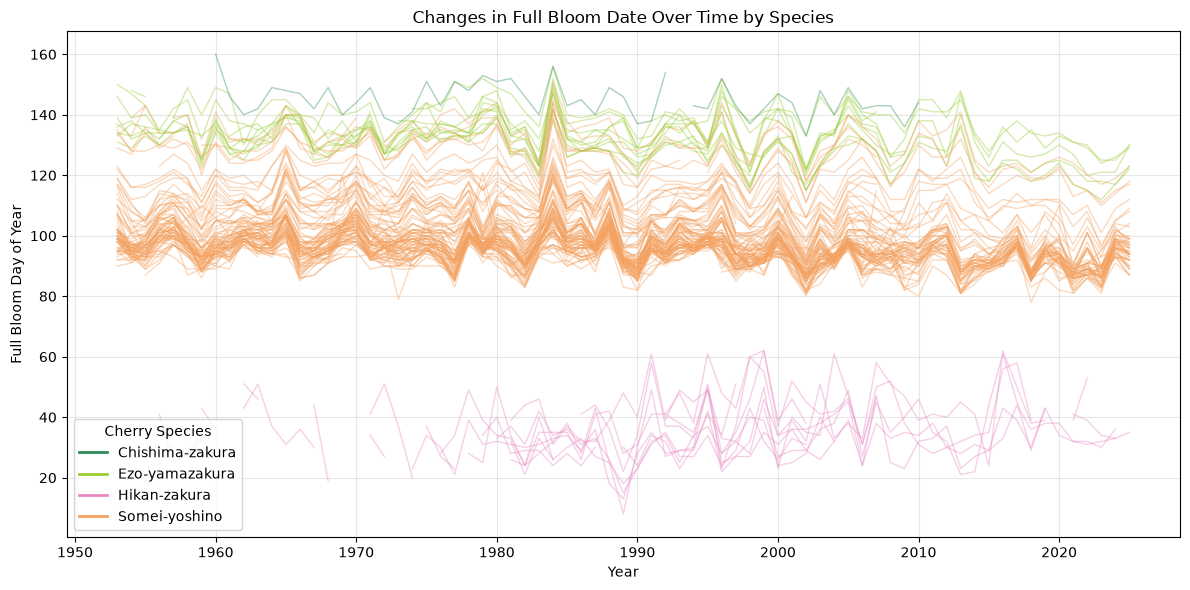

In [199]:
from matplotlib.lines import Line2D

# Assign one color to each species.
sakura_species = sorted(all_full_bloom['cherry_species'].dropna().unique())
palette = ["#2E8B57", "#9ACD32", "#E78AC3", "#F4A261"]
colors = dict(zip(sakura_species, palette))

plt.figure(figsize=(12, 6))

# Group by station and species to handle changes in species.
for (station_id, cherry_species), group in all_full_bloom.groupby(
    ["station_id", "cherry_species"]
):
    group = group.sort_values("year")

    plt.plot(
        group["year"],
        group["full_bloom_doy"],
        alpha=0.4,
        linewidth=1,
        color=colors[cherry_species],
    )
    
# Show one legend entry per species.
handles = [
    Line2D([0], [0], color=colors[name], linewidth=2, label=name)
    for name in sakura_species
]
plt.legend(handles=handles, title="Cherry Species")

plt.xlabel("Year")
plt.ylabel("Full Bloom Day of Year")
plt.title("Changes in Full Bloom Date Over Time by Species")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

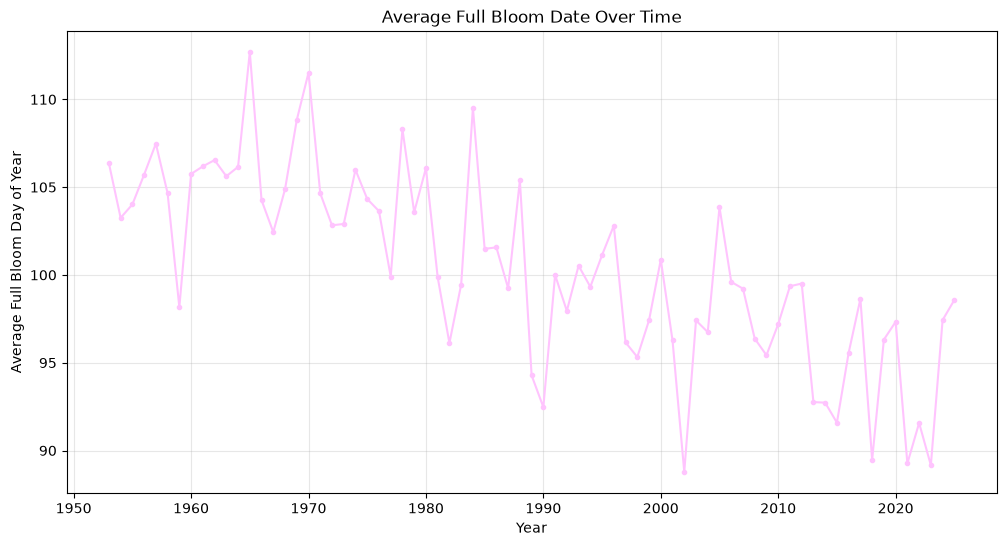

In [200]:
yearly_avg = (
    full_bloom
    .groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_avg["year"],
    yearly_avg["full_bloom_doy"],
    marker="o",
    markersize=3,
    color ="#FFC4FE"
)

plt.xlabel("Year")
plt.ylabel("Average Full Bloom Day of Year")
plt.title("Average Full Bloom Date Over Time")

plt.grid(alpha=0.3)
plt.show()

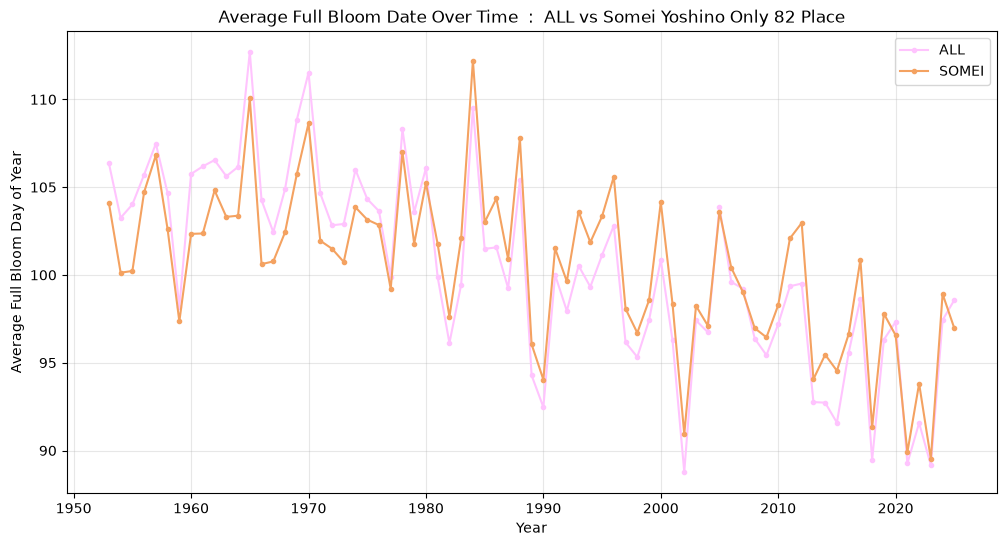

In [201]:
yearly_avg = (
    full_bloom
    .groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

somei_yearly_avg = (
    somei_full_bloom
    .groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)


plt.figure(figsize=(12, 6))

plt.plot(
    yearly_avg["year"],
    yearly_avg["full_bloom_doy"],
    marker="o",
    markersize=3,
    color ="#FFC4FE",
    label='ALL'
)


plt.plot(
    somei_yearly_avg["year"],
    somei_yearly_avg["full_bloom_doy"],
    marker="o",
    markersize=3,
    color ="#F4A261",
    label='SOMEI'
)


plt.xlabel("Year")
plt.ylabel("Average Full Bloom Day of Year")
plt.title("Average Full Bloom Date Over Time  :  ALL vs Somei Yoshino Only 82 Place")
plt.legend()

plt.grid(alpha=0.3)
plt.show()

The average full bloom date shows a clear downward trend over time, suggesting that cherry blossoms are generally reaching full bloom earlier in recent decades. Despite substantial variation across stations and years, this overall shift is visible across the dataset.

### drop null

In [202]:
full_bloom = full_bloom.dropna(subset=["full_bloom_doy"])

In [203]:
somei_full_bloom_dropna = somei_full_bloom.dropna(subset=["full_bloom_doy"])

print('Missing value before', somei_full_bloom['full_bloom_doy'].isna().sum())
print('Missing value after', somei_full_bloom_dropna['full_bloom_doy'].isna().sum())

Missing value before 825
Missing value after 0


### Visualization after dropping null

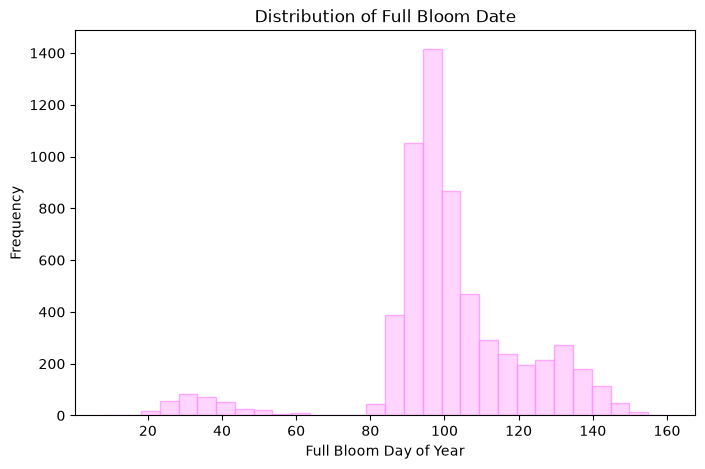

In [204]:
plt.figure(figsize=(8, 5))

plt.hist(full_bloom["full_bloom_doy"], bins=30, edgecolor="#FF89FD",fill=True, alpha=0.7, color="#FFC4FE")

plt.xlabel("Full Bloom Day of Year")
plt.ylabel("Frequency")
plt.title("Distribution of Full Bloom Date")

plt.show()

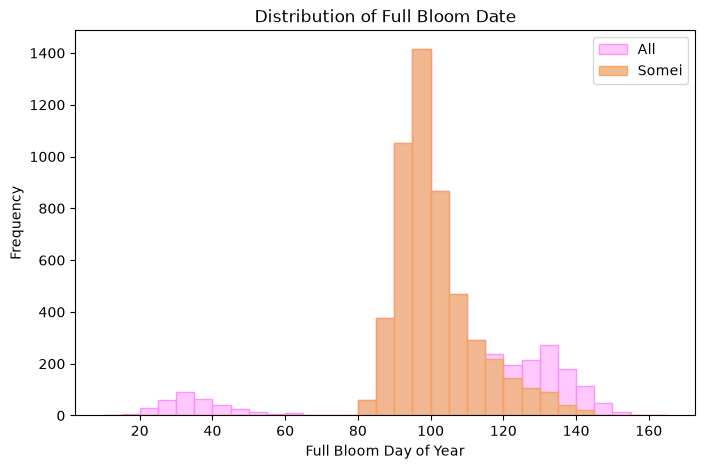

In [205]:
plt.figure(figsize=(8, 5))

plt.hist(full_bloom["full_bloom_doy"], bins=np.arange(10,170,5), edgecolor="#FF89FD",fill=True, alpha=0.9, color="#FFC4FE", label='All')
plt.hist(somei_full_bloom_dropna["full_bloom_doy"], bins=np.arange(10,170,5), edgecolor="#F4A261",fill=True, alpha=0.9, color="#EFB584", label='Somei')

plt.xlabel("Full Bloom Day of Year")
plt.ylabel("Frequency")
plt.title("Distribution of Full Bloom Date")
plt.legend()

plt.show()

Full bloom dates are mainly concentrated around days 90–110, while smaller groups bloom much earlier or later, indicating substantial variation across stations.

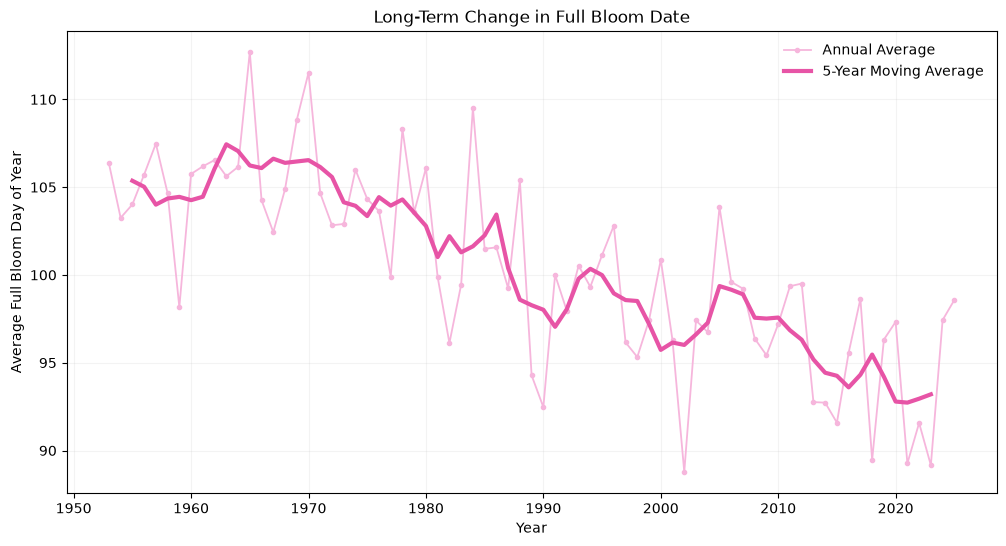

In [206]:
yearly = (
    full_bloom.groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

yearly["rolling_5yr"] = (
    yearly["full_bloom_doy"]
    .rolling(5, center=True)
    .mean()
)

plt.figure(figsize=(12, 6))

plt.plot(
    yearly["year"],
    yearly["full_bloom_doy"],
    color="#f6b6dc",
    marker="o",
    markersize=3,
    linewidth=1.3,
    label="Annual Average"
)

plt.plot(
    yearly["year"],
    yearly["rolling_5yr"],
    color="#e754a6",
    linewidth=3,
    label="5-Year Moving Average"
)

plt.xlabel("Year")
plt.ylabel("Average Full Bloom Day of Year")
plt.title("Long-Term Change in Full Bloom Date")
plt.legend(frameon=False)
plt.grid(alpha=0.15)
plt.show()

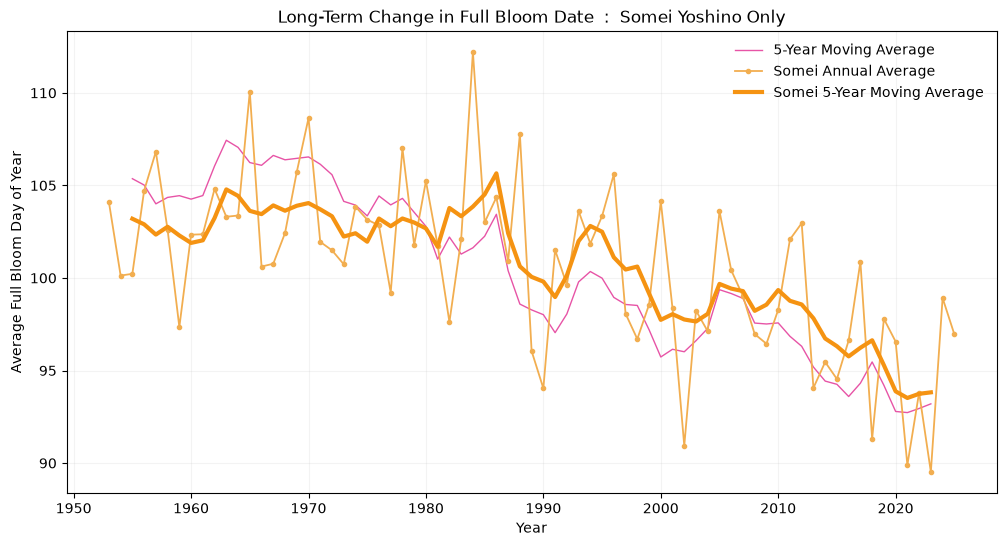

In [207]:
yearly = (
    full_bloom.groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

yearly["rolling_5yr"] = (
    yearly["full_bloom_doy"]
    .rolling(5, center=True)
    .mean()
)

somei_yearly = (
    somei_full_bloom_dropna.groupby("year")["full_bloom_doy"]
    .mean()
    .reset_index()
)

somei_yearly["rolling_5yr"] = (
    somei_yearly["full_bloom_doy"]
    .rolling(5, center=True)
    .mean()
)

plt.figure(figsize=(12, 6))

# plt.plot(
#     yearly["year"],
#     yearly["full_bloom_doy"],
#     color="#f6b6dc",
#     marker="o",
#     markersize=3,
#     linewidth=1.3,
#     label="Annual Average"
# )

plt.plot(
    yearly["year"],
    yearly["rolling_5yr"],
    color="#e754a6",
    linewidth=1,
    label="5-Year Moving Average"
)

plt.plot(
    somei_yearly["year"],
    somei_yearly["full_bloom_doy"],
    color="#f2ae50",
    marker="o",
    markersize=3,
    linewidth=1.3,
    label="Somei Annual Average"
)

plt.plot(
    somei_yearly["year"],
    somei_yearly["rolling_5yr"],
    color="#f59312",
    linewidth=3,
    label="Somei 5-Year Moving Average"
)

plt.xlabel("Year")
plt.ylabel("Average Full Bloom Day of Year")
plt.title("Long-Term Change in Full Bloom Date  :  Somei Yoshino Only")
plt.legend(frameon=False)
plt.grid(alpha=0.15)
plt.show()

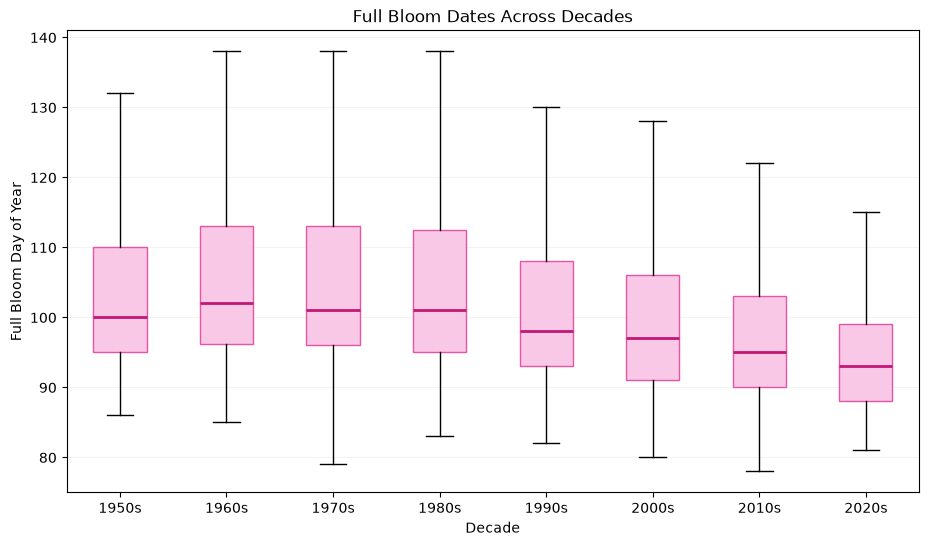

In [208]:
full_bloom["decade"] = (full_bloom["year"] // 10) * 10

decades = sorted(full_bloom["decade"].unique())

data = [
    full_bloom.loc[
        full_bloom["decade"] == decade,
        "full_bloom_doy"
    ]
    for decade in decades
]

plt.figure(figsize=(11, 6))

bp = plt.boxplot(
    data,
    tick_labels=[f"{d}s" for d in decades],
    patch_artist=True,
    showfliers=False
)

for box in bp["boxes"]:
    box.set_facecolor("#f8c8e6")
    box.set_edgecolor("#e754a6")

for median in bp["medians"]:
    median.set_color("#c21875")
    median.set_linewidth(2)

plt.xlabel("Decade")
plt.ylabel("Full Bloom Day of Year")
plt.title("Full Bloom Dates Across Decades")

plt.grid(axis="y", alpha=0.15)
plt.show()

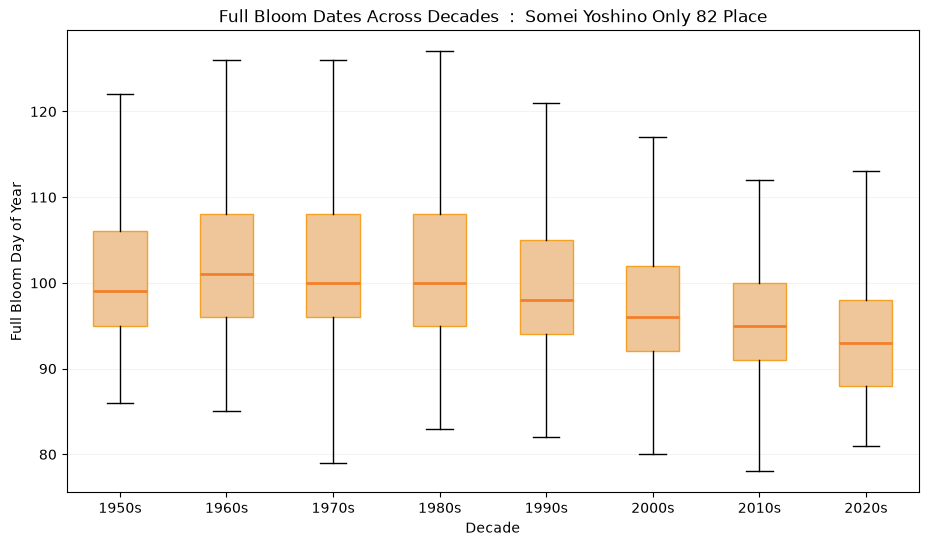

In [209]:
somei_full_bloom_dropna["decade"] = (somei_full_bloom_dropna["year"] // 10) * 10

decades = sorted(somei_full_bloom_dropna["decade"].unique())

data = [
    somei_full_bloom_dropna.loc[
        somei_full_bloom_dropna["decade"] == decade,
        "full_bloom_doy"
    ]
    for decade in decades
]

plt.figure(figsize=(11, 6))

bp = plt.boxplot(
    data,
    tick_labels=[f"{d}s" for d in decades],
    patch_artist=True,
    showfliers=False
)

for box in bp["boxes"]:
    box.set_facecolor("#eec69a")
    box.set_edgecolor("#f5a124")

for median in bp["medians"]:
    median.set_color("#f47f2b")
    median.set_linewidth(2)

plt.xlabel("Decade")
plt.ylabel("Full Bloom Day of Year")
plt.title("Full Bloom Dates Across Decades  :  Somei Yoshino Only 82 Place")

plt.grid(axis="y", alpha=0.15)
plt.show()

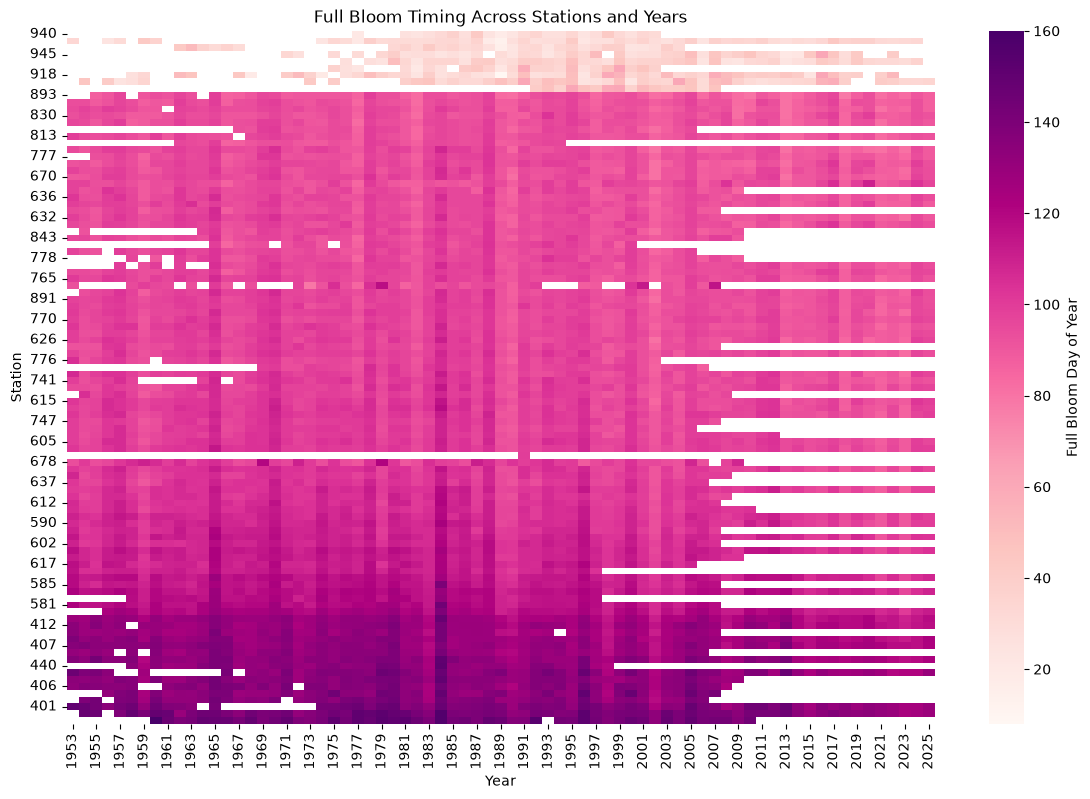

In [210]:
heatmap_data = full_bloom.pivot_table(
    index="station_id",
    columns="year",
    values="full_bloom_doy"
)


order = heatmap_data.mean(axis=1).sort_values().index
heatmap_data = heatmap_data.loc[order]

plt.figure(figsize=(14, 9))

sns.heatmap(
    heatmap_data,
    cmap="RdPu",
    cbar_kws={"label": "Full Bloom Day of Year"}
)

plt.xlabel("Year")
plt.ylabel("Station")
plt.title("Full Bloom Timing Across Stations and Years")

plt.show()

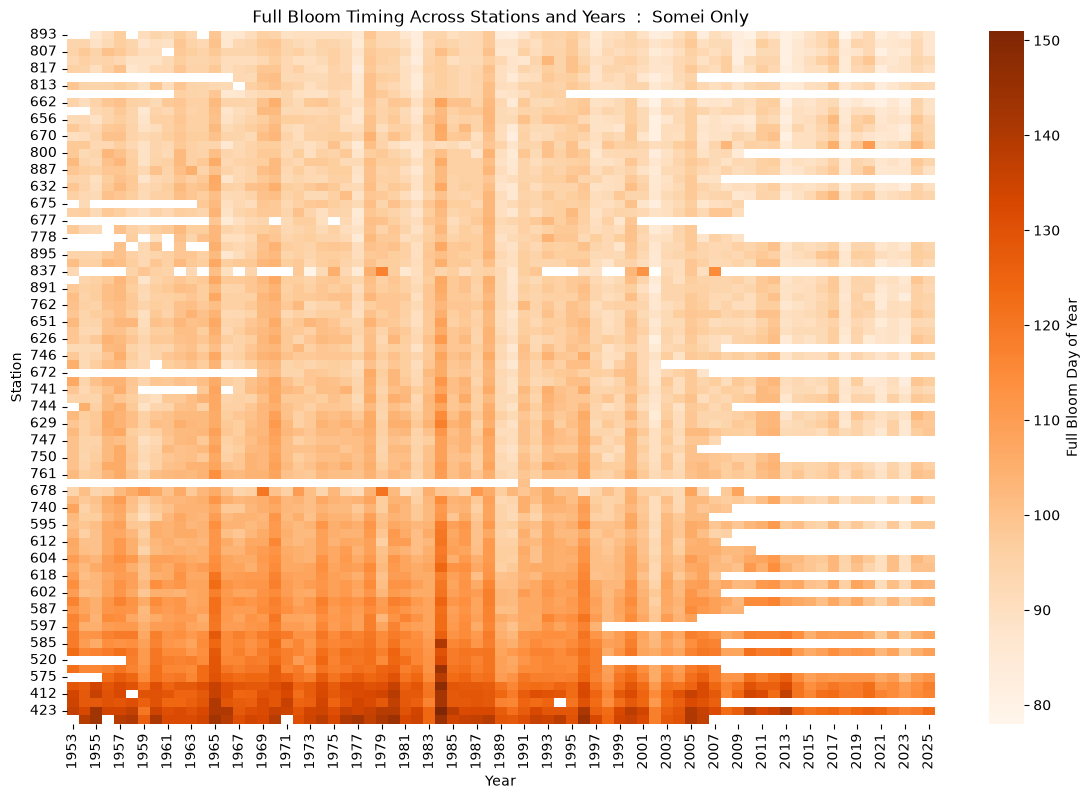

In [211]:
heatmap_data = somei_full_bloom_dropna.pivot_table(
    index="station_id",
    columns="year",
    values="full_bloom_doy"
)


order = heatmap_data.mean(axis=1).sort_values().index
heatmap_data = heatmap_data.loc[order]

plt.figure(figsize=(14, 9))

sns.heatmap(
    heatmap_data,
    cmap="Oranges",
    cbar_kws={"label": "Full Bloom Day of Year"}
)

plt.xlabel("Year")
plt.ylabel("Station")
plt.title("Full Bloom Timing Across Stations and Years  :  Somei Only")

plt.show()

Full bloom timing varies substantially across stations, reflecting strong regional intervalerences in flowering patterns. Despite these intervalerences, many stations show a gradual shift toward earlier full bloom dates over time.

(Natsumi) Why are sakura flowering dates records missing at some whether stations from 2007 onward? 
- JMA automated many weather stations between 2007 and 2009
- Weather measurements continued, but cherry blossom observations ended at some stations because they required people to check the trees in person

We should dicuss: 
- Should we limit both the training and test datasets to stations with flowering records in 2025?

In [212]:
sta_2025 = somei_full_bloom_dropna.query('year==2025')['station_id']
num_2025 = sta_2025.nunique()

list_2025 = sta_2025.to_list()
all_record = len(somei_full_bloom_dropna)
somei_record = len(somei_full_bloom_dropna.query('station_id==@list_2025'))

print("Number of stations with full bloom records in 2025:", num_2025)
print("Number of Somei-yoshino records across all stations since 1953:", all_record)
print("Number of Somei-yoshino records since 1953 at stations with records in 2025:", somei_record)


Number of stations with full bloom records in 2025: 48
Number of Somei-yoshino records across all stations since 1953: 5161
Number of Somei-yoshino records since 1953 at stations with records in 2025: 3477


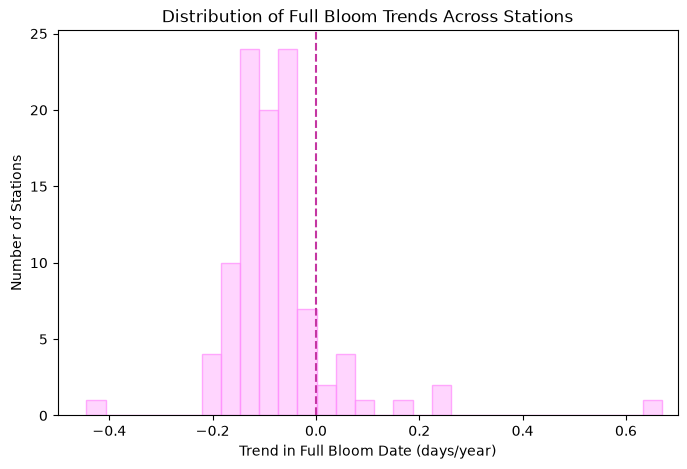

In [213]:
station_trends = []

for station_id, group in full_bloom.groupby("station_id"):
    
    if len(group) >= 10:
        slope = np.polyfit(
            group["year"],
            group["full_bloom_doy"],
            1
        )[0]
        
        station_trends.append(slope)

plt.figure(figsize=(8, 5))

plt.hist(station_trends, bins=30, edgecolor="#FF89FD", alpha=0.7, color="#FFC4FE")

plt.axvline(0, linestyle="--", color="#C436A2", label="No Trend")

plt.xlabel("Trend in Full Bloom Date (days/year)")
plt.ylabel("Number of Stations")
plt.title("Distribution of Full Bloom Trends Across Stations")
plt.xlim(-0.5, 0.7)

plt.show()

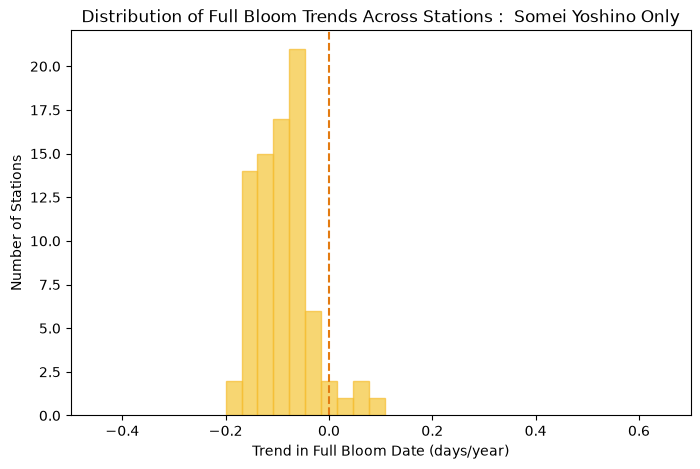

In [214]:
station_trends = []

for station_id, group in somei_full_bloom_dropna.groupby("station_id"):
    
    if len(group) >= 10:
        slope = np.polyfit(
            group["year"],
            group["full_bloom_doy"],
            1
        )[0]
        
        station_trends.append(slope)

plt.figure(figsize=(8, 5))

plt.hist(station_trends, bins=10, edgecolor="#F6BD30", alpha=0.7, color="#F4C536")

plt.axvline(0, linestyle="--", color="#E37B12", label="No Trend")

plt.xlabel("Trend in Full Bloom Date (days/year)")
plt.ylabel("Number of Stations")
plt.title("Distribution of Full Bloom Trends Across Stations :  Somei Yoshino Only")
plt.xlim(-0.5, 0.7)

plt.show()

Most stations show negative trends, suggesting that full bloom dates have generally become earlier over time, although a few stations show later blooming trends.

In [215]:
# save cleaned dataset as csv
# OUTPUT_FILE = (
#     PROJECT_DIR
#     / "data/processed/02_cleaned_source_data/cleaned_full_bloom_data.csv"
# )
# full_bloom[['station_id','year','full_bloom_date','full_bloom_doy']].to_csv(OUTPUT_FILE, index=False)

---------------------------------------------

## 2. Time between flowering and full bloom

### Preprocess

transform the date to day of yaer

In [265]:
flower["bloom_date"] = pd.to_datetime(
    flower["bloom_date"],
    dayfirst=True
)
flower["bloom_doy"] = flower["bloom_date"].dt.dayofyear
flower[["station_id", "year", "bloom_date", "bloom_doy"]].head()

,station_id,year,bloom_date,bloom_doy
0,401,1953,1953-05-21,141.0
1,401,1954,1954-05-17,137.0
2,401,1955,1955-05-17,137.0
3,401,1956,1956-05-12,133.0
4,401,1957,1957-05-18,138.0


filter for Somei-Yoshino

In [266]:
all_flower = pd.merge(
    flower,
    species,
    on='station_id',
    how='left'
)
print('Before', flower.shape)
print('Merge species', all_flower.shape) 

somei_flower = all_flower.query('cherry_species == "Somei-yoshino"')
print('Filter for somei-yoshino', somei_flower.shape)
print('Number of Somei-Yoshino station', somei_flower['station_id'].nunique())


Before (7446, 4)
Merge species (7446, 5)
Filter for somei-yoshino (5986, 5)
Number of Somei-Yoshino station 82


drop null

In [267]:
somei_flower_dropna = somei_flower.dropna(subset=["bloom_doy"])

print('Missing value before', somei_flower['bloom_doy'].isna().sum())
print('Missing value after', somei_flower_dropna['bloom_doy'].isna().sum())

Missing value before 794
Missing value after 0


merge the flowering date data with the full bloom date data.

In [268]:
key = ['station_id','year']
columns = key + ['bloom_date'] + ['bloom_doy']

merge_day = somei_full_bloom_dropna.merge(
    somei_flower_dropna[columns],
    on = key,
    how='inner'    
)

print('Full bloom day data', somei_full_bloom_dropna.shape)
print('Flower day data', somei_flower_dropna.shape)
print('Merge data : inner join', merge_day.shape) 
print('Some records have only a bloom date or a flower date')
print('The following analysis usese an inner join to include only records with both date')

Full bloom day data (5161, 6)
Flower day data (5192, 5)
Merge data : inner join (5142, 8)
Some records have only a bloom date or a flower date
The following analysis usese an inner join to include only records with both date


how flowering and full bloom dates vary across years and locations

In [269]:
merge_day['interval'] = merge_day['full_bloom_doy'] - merge_day['bloom_doy']
merge_day.head(2)

,station_id,year,full_bloom_date,full_bloom_doy,cherry_species,decade,bloom_date,bloom_doy,interval
0,412,1953,1953-05-14,134.0,Somei-yoshino,1950,1953-05-07,127.0,7.0
1,412,1954,1954-05-08,128.0,Somei-yoshino,1950,1954-05-04,124.0,4.0


### Descriptive Statistics of the Flowering-to-Full-Bloom Interval

In [278]:
print(merge_day['interval'].describe())

count    5142.000000
mean        6.610074
std         2.745908
min         1.000000
25%         5.000000
50%         6.000000
75%         8.000000
max        26.000000
Name: interval, dtype: float64


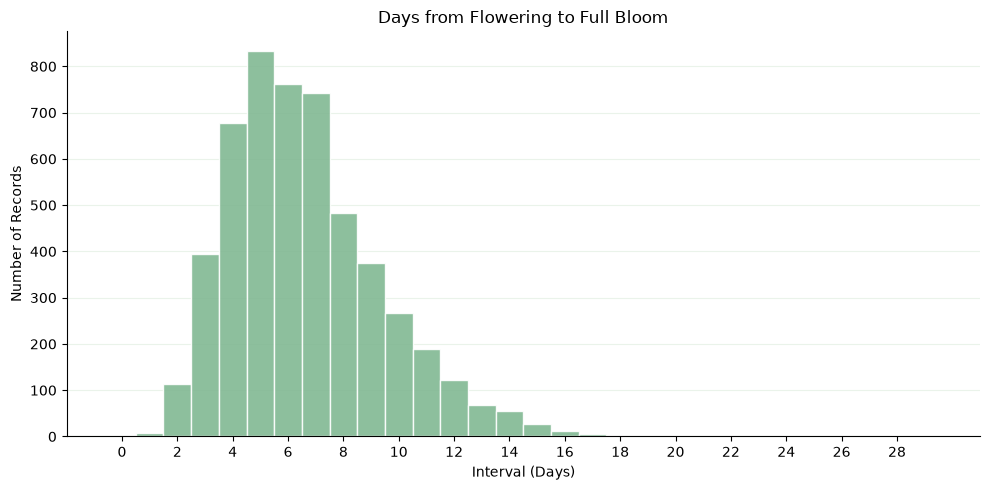

In [279]:
plt.figure(figsize=(10, 5))

plt.hist(
    merge_day['interval'].dropna(),
    bins=np.arange(-0.5, 30.5, 1),
    color='#81B893',
    edgecolor='white',
    alpha=0.9
)

plt.title('Days from Flowering to Full Bloom')
plt.xlabel('Interval (Days)')
plt.ylabel('Number of Records')
plt.xticks(np.arange(0, 30, 2))
plt.grid(axis='y', color='#DCEBDD', alpha=0.6)
plt.gca().set_axisbelow(True)
plt.gca().spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

C:\Users\natsu\AppData\Local\Temp\ipykernel_11524\2188315060.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


<function matplotlib.pyplot.show(close=None, block=None)>

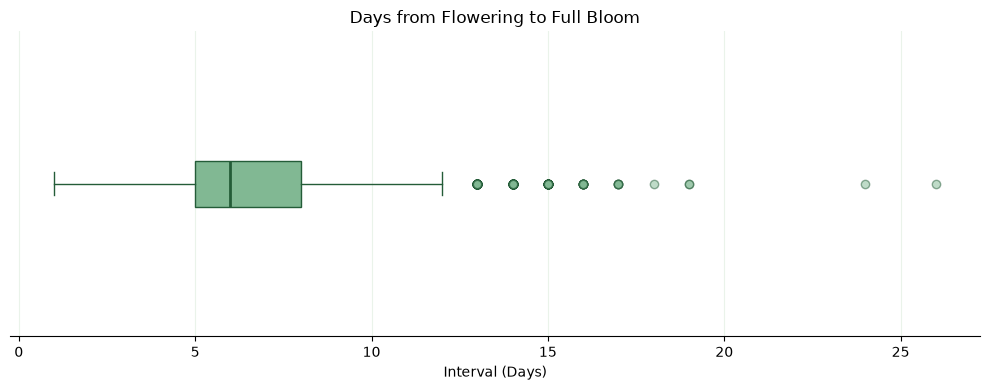

In [282]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    merge_day['interval'].dropna(),
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor='#81B893', edgecolor='#245C38'),
    medianprops=dict(color='#245C38', linewidth=2),
    whiskerprops=dict(color='#245C38'),
    capprops=dict(color='#245C38'),
    flierprops=dict(marker='o', markerfacecolor='#81B893',
                    markeredgecolor='#245C38', alpha=0.5)
)

plt.title('Days from Flowering to Full Bloom')
plt.xlabel('Interval (Days)')
plt.yticks([])
plt.grid(axis='x', color='#DCEBDD', alpha=0.6)
plt.gca().set_axisbelow(True)
plt.gca().spines[['top', 'right', 'left']].set_visible(False)

plt.tight_layout()
plt.show

In [285]:
merge_day.loc[merge_day['interval'] >= 20]

,station_id,year,full_bloom_date,full_bloom_doy,cherry_species,decade,bloom_date,bloom_doy,interval
4752,837,2001,2001-04-23,113.0,Somei-yoshino,2000,2001-03-28,87.0,26.0
4757,837,2007,2007-04-25,115.0,Somei-yoshino,2000,2007-04-01,91.0,24.0


- The interval is generally between 3 and 9 days. 
- Some outliers appear above the upper whisker of the box plot.

### Two-way Anova

In [270]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

df = merge_day.dropna(subset=['interval', 'station_id', 'year']).copy()

model = ols('interval ~ C(station_id) + C(year)', data=df).fit()

anova = sm.stats.anova_lm(model, typ=2)
print(anova)

                     sum_sq      df          F         PR(>F)
C(station_id)  12832.422374    81.0  40.537450   0.000000e+00
C(year)         6253.759921    72.0  22.224987  1.316300e-244
Residual       19493.671602  4988.0        NaN            NaN


- The two-way ANOVA showed that the interval between flowering and full bloom differed significantly across both stations and years (p < 0.001 for both).

### Interval across Years

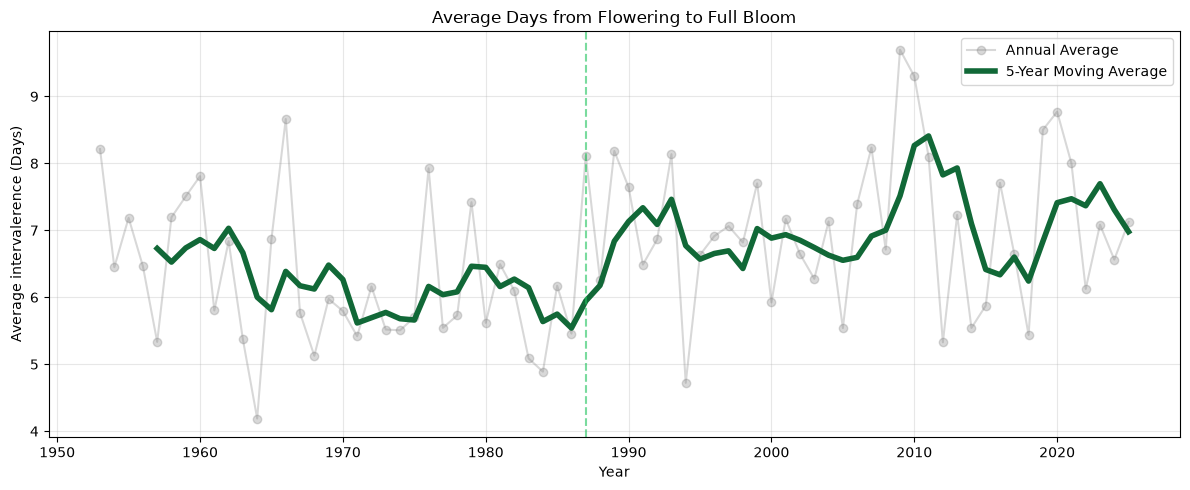

In [271]:
import matplotlib.pyplot as plt

yearly_interval = merge_day.groupby('year')['interval'].mean()
yearly_interval = yearly_interval.reindex(
    range(int(yearly_interval.index.min()), int(yearly_interval.index.max()) + 1)
)
average_5yr = yearly_interval.rolling(window=5, min_periods=5).mean()

plt.figure(figsize=(12, 5))

plt.plot(yearly_interval.index, yearly_interval,
         color='gray', alpha=0.3, label='Annual Average',  marker='o')

plt.plot(average_5yr.index, average_5yr,
         color="#116837", linewidth=4, label='5-Year Moving Average')

plt.title('Average Days from Flowering to Full Bloom')
plt.xlabel('Year')
plt.ylabel('Average intervalerence (Days)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.axvline(x=1987, color="#22C35D", linestyle='--', alpha=0.6)
plt.show()

Notes:

Examine how the time from flowering to full bloom changes over time.
- Annual average: 
  - 4–10 days
- 5-year moving average:
    - Approximately 5–8 days 
- The time from flowering to full bloom appears to have increased slightly.
    - up to 1987: 5–7 days 
    - from 1988 onward: 6–8 days 


### Interval across Stations

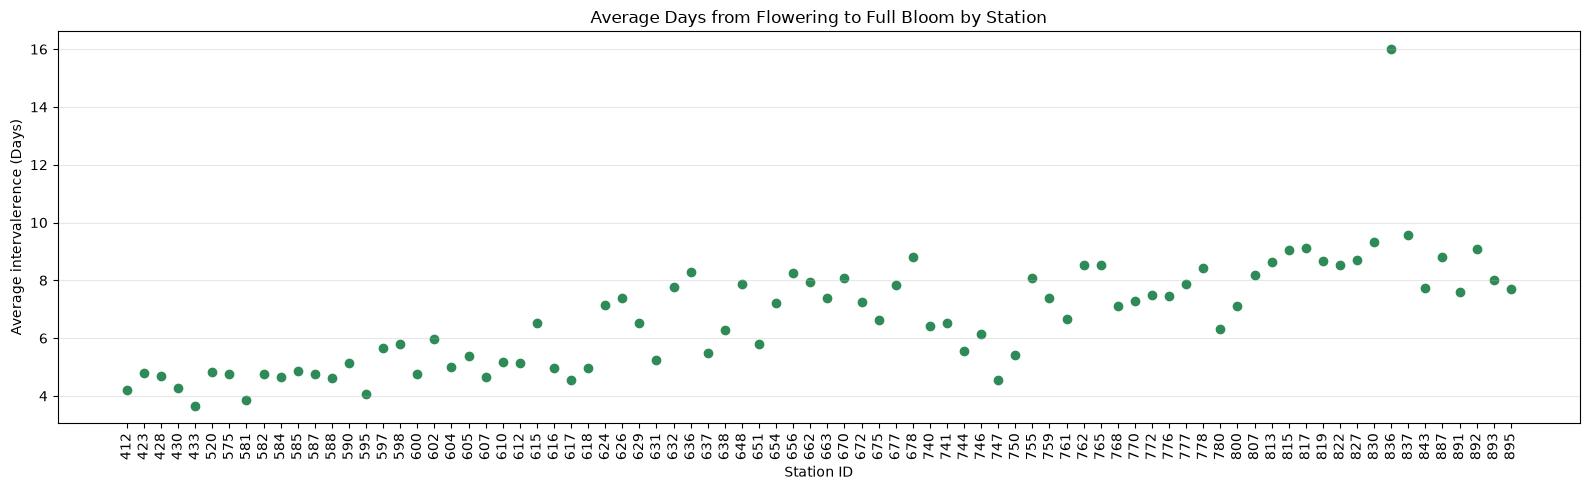

In [272]:
import matplotlib.pyplot as plt

station_interval = merge_day.groupby('station_id')['interval'].mean()

plt.figure(figsize=(16, 5))
plt.scatter(station_interval.index.astype(str), station_interval.values,
            color='#2E8B57')

plt.title('Average Days from Flowering to Full Bloom by Station')
plt.xlabel('Station ID')
plt.ylabel('Average intervalerence (Days)')
plt.xticks(rotation=90)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

Notes:

Examined whether the time from flowering to full bloom intervalers across stations.
- The interval tends to be longer at stations farther south.
(Stations with higher IDs are generally located farther south.)

- station_id == 837 can be outlier

---------------------------------------------

### Discarded Analysis

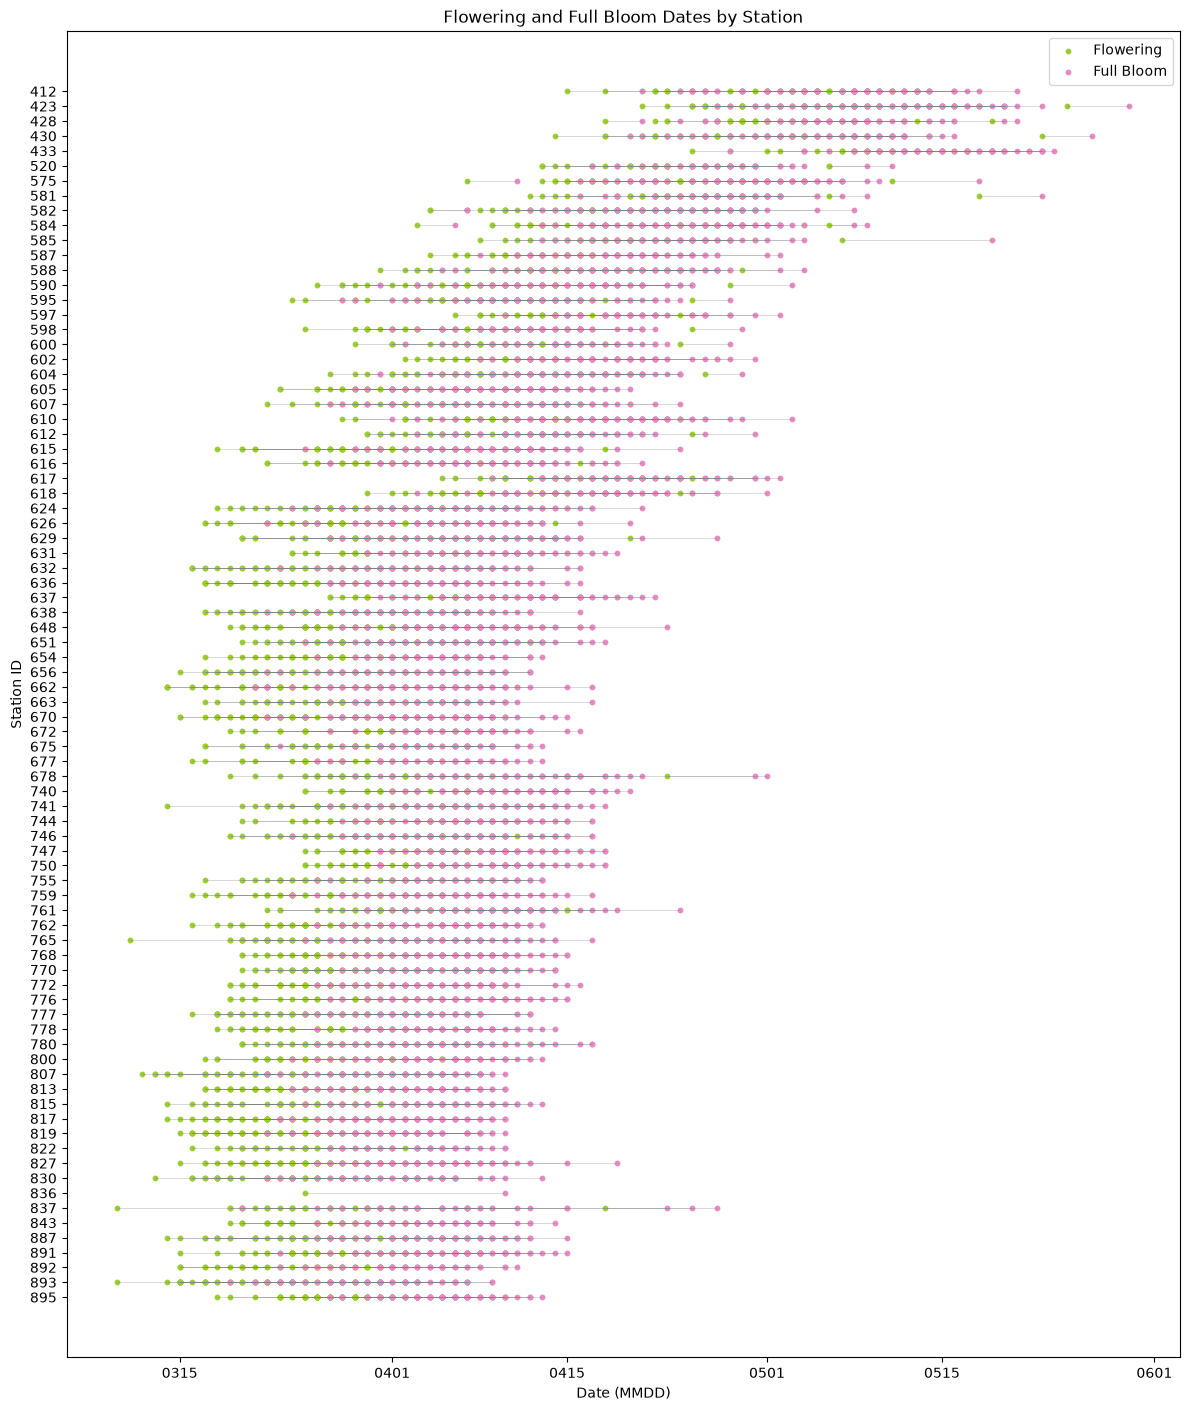

In [286]:
import matplotlib.dates as mdates

df = merge_day.dropna(subset=['bloom_date', 'full_bloom_date']).copy()

for col in ['bloom_date', 'full_bloom_date']:
    df[col] = pd.to_datetime(
        '2000-' + pd.to_datetime(df[col]).dt.strftime('%m-%d')
    )

stations = sorted(df['station_id'].unique())
y = df['station_id'].map({station: i for i, station in enumerate(stations)})

fig, ax = plt.subplots(figsize=(12, 14))

ax.hlines(y, df['bloom_date'], df['full_bloom_date'],
          color='gray', alpha=0.3, linewidth=0.7)

ax.scatter(df['bloom_date'], y,
           color='#9ACD32', s=10, label='Flowering')

ax.scatter(df['full_bloom_date'], y,
           color='#E78AC3', s=10, label='Full Bloom')

ax.set_yticks(range(len(stations)))
ax.set_yticklabels(stations)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m%d'))

ax.set_xlabel('Date (MMDD)')
ax.set_ylabel('station_id')
ax.invert_yaxis()
ax.legend()
plt.tight_layout()

ax.set_title('Flowering and Full Bloom Dates by Station')
ax.set_xlabel('Date (MMDD)')
ax.set_ylabel('Station ID')

plt.show()